# Power Outage Magnitude Prediction Using PySpark (Regression)
**Course:** B.Tech 5th Semester - Big Data Analytics  
**Models Evaluated (`Spark MLlib`):**
1. **Linear Regression** (`pyspark.ml.regression.LinearRegression`) — Regularized ElasticNet linear model
2. **Random Forest Regressor** (`pyspark.ml.regression.RandomForestRegressor`) — Parallel bootstrap-aggregated decision tree ensemble
3. **Gradient-Boosted Tree Regressor** (`pyspark.ml.regression.GBTRegressor`) — Sequential stagewise additive gradient-boosting tree ensemble

---

## 1. Objective

The goal of this notebook is to build and compare three distributed regression models in **PySpark** to predict hourly customer power outage counts during active National Weather Service (NWS) weather alerts across U.S. counties.

Because raw customer outage counts span several orders of magnitude, we predict the log-transformed target:
$$y_{i,t} = \log(1 + \text{max\_rolling\_avg}_{i,t})$$
for county $i$ at hour $t$, using past outage observations from the same event ($t-1$ and $t-2$), initial event magnitude ($t_0$), elapsed event hours, county baseline outage levels, active weather hazard types, and WFO warning area statistics across $843,512$ verified $100\%$-complete continuation county-hours. We also perform an **Execution-Time and Scalability Analysis** across dataset scale fractions ($25\%, 50\%, 75\%, 100\%$) and Spark partition counts ($4, 8, 16$).

## 2. Problem Statement and Research Questions

### 2.1 Problem Statement
During extreme weather events (thunderstorms, tornadoes, winter storms, high winds, and heatwaves), electric utilities need reliable 1-hour-ahead estimates of customer outages to allocate repair crews effectively. Working with the EAGLE-I outage dataset and NWS weather warning logs involves three practical challenges:
1. **Large Data Volume:** Processing and joining $3.57\text{ million}$ hourly outage rows with $4.15\text{ million}$ NWS warning records and $1.05\text{ million}$ daily availability records requires distributed query execution in PySpark rather than single-threaded pandas.
2. **Incomplete Telemetry Bias:** The `max_rolling_avg` column averages customer outages over a 4-hour rolling window ($16$ fifteen-minute intervals). As shown in `Missing_Data_Sensitivity_Summary.csv`, when `source_completeness_pct < 100%`, missing intervals pull the rolling average down by $18.75\%$ to $75.0\%$. Missing records indicate unrecorded telemetry snapshots rather than zero outages.
3. **Non-Linear Storm Dynamics:** During the early hours of an outage event ($1 \le h \le 3$), outage counts change rapidly before stabilizing in later hours ($h \ge 4$).

### 2.2 Research Questions
1. How does filtering to $100\%$-complete telemetry records and applying a $\log(1 + y)$ transformation improve target stability?
2. How do **Linear Regression**, **Random Forest Regressor**, and **Gradient-Boosted Tree Regressor (`GBTRegressor`)** compare on out-of-time test data (2022-2023) across **MAE**, **RMSE**, and **$R^2$**?
3. How does prediction error differ between early storm propagation hours ($1 \le h \le 3$) and sustained outage hours ($h \ge 4$)?
4. How does training and evaluation time scale across dataset sizes ($25\%$ to $100\%$) and Spark partition counts ($4, 8, 16$)?

## 3. Environment and Spark Configuration

We process four CSV files totaling **8.77 million rows** ($\approx 1.23\text{ GB}$):
- `Eagle_I_US_2024_with_VTEC_Updated.csv` ($3,572,394$ rows)
- `NWS_WARNINGS_COMBINED_data_Updated.csv` ($4,152,437$ rows)
- `EAGLEI_Source_Record_Availability.csv` ($1,048,575$ rows)
- `Missing_Data_Sensitivity_Summary.csv` ($4$ rows)

PySpark handles the distributed joins and window functions (`Window.partitionBy("fips_code", "new_event_no").orderBy("event_ts")`), caches the training/validation/test splits in memory during model fitting, and saves the processed feature table in **Parquet** format.

In [1]:
import os
import sys
import time
import json
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import pyarrow.parquet as pq

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="deep")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler,
)
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

WORKSPACE_Candidates = [
    Path(os.environ.get("GRIDPULSE_DATA_DIR", "")).resolve() if os.environ.get("GRIDPULSE_DATA_DIR") else None,
    Path.cwd().parent.resolve(),
    Path.cwd().resolve(),
]
DATA_DIR = None
for cand in WORKSPACE_Candidates:
    if cand and (cand / "Eagle_I_US_2024_with_VTEC_Updated.csv").exists():
        DATA_DIR = cand
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate 'Eagle_I_US_2024_with_VTEC_Updated.csv'. "
        "Set environment variable GRIDPULSE_DATA_DIR or place the raw CSVs in the parent workspace directory."
    )

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "GridPulse_Part1_Team_Evaluation" and (NOTEBOOK_DIR / "GridPulse_Part1_Team_Evaluation").exists():
    NOTEBOOK_DIR = (NOTEBOOK_DIR / "GridPulse_Part1_Team_Evaluation").resolve()

OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PATHS = {
    "outage": DATA_DIR / "Eagle_I_US_2024_with_VTEC_Updated.csv",
    "avail": DATA_DIR / "EAGLEI_Source_Record_Availability.csv",
    "nws": DATA_DIR / "NWS_WARNINGS_COMBINED_data_Updated.csv",
    "sensitivity": DATA_DIR / "Missing_Data_Sensitivity_Summary.csv",
}

for name, p in PATHS.items():
    if not p.exists() or p.stat().st_size == 0:
        raise FileNotFoundError(f"Required dataset '{name}' is missing or empty at: {p}")

spark = (
    SparkSession.builder
    .appName("GridPulse_Part1_Regression")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("=== Environment & Spark Configuration Summary ===")
print(f"Operating System : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Python Version   : {sys.version.split()[0]}")
print(f"Spark Version    : {spark.version}")
print(f"Java Version     : {spark.sparkContext._jvm.java.lang.System.getProperty('java.version')}")
print(f"Default Parallel : {spark.sparkContext.defaultParallelism} cores")
print(f"Data Directory   : {DATA_DIR}")
print(f"Output Directory : {OUTPUT_DIR}")

=== Environment & Spark Configuration Summary ===
Operating System : Windows 11 (AMD64)
Python Version   : 3.12.10
Spark Version    : 4.2.0
Java Version     : 17.0.12
Default Parallel : 16 cores
Data Directory   : C:\Users\jsm10\OneDrive\Desktop\bda_project
Output Directory : C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs


## 4. Dataset Description and Schema

All four datasets are loaded using explicit Spark schemas (`StructType`) to avoid extra file scans:
1. **`Eagle_I_US_2024_with_VTEC_Updated.csv` ($3,572,394$ rows):** Hourly county outage measurements (`max_rolling_avg`) matched with active NWS VTEC weather alerts across $3,010$ U.S. counties (2015-2023).
2. **`EAGLEI_Source_Record_Availability.csv` ($1,048,575$ rows):** Daily counts of expected ($96$) vs. observed 15-minute telemetry records per county (`fips_code <= 12033`).
3. **`NWS_WARNINGS_COMBINED_data_Updated.csv` ($4,152,437$ rows):** NWS VTEC warning records containing WFO codes, issuance/expiration timestamps, phenomenon codes (`PHENOM`), significance levels (`SIG`), and warning polygon areas (`AREA_KM2`).
4. **`Missing_Data_Sensitivity_Summary.csv` ($4$ rows):** Summary table showing how incomplete telemetry affects rolling outage averages.

In [2]:
outage_schema = T.StructType([
    T.StructField("fips_code", T.IntegerType(), True),
    T.StructField("Hour", T.StringType(), True),
    T.StructField("max_rolling_avg", T.DoubleType(), True),
    T.StructField("state", T.StringType(), True),
    T.StructField("county", T.StringType(), True),
    T.StructField("median_sum", T.DoubleType(), True),
    T.StructField("new_event_no", T.IntegerType(), True),
    T.StructField("evDur_Hr", T.IntegerType(), True),
    T.StructField("evDur_day", T.IntegerType(), True),
    T.StructField("Max_outage", T.DoubleType(), True),
    T.StructField("source_completeness_pct", T.DoubleType(), True),
    T.StructField("event_mean_completeness_pct", T.DoubleType(), True),
    T.StructField("event_min_completeness_pct", T.DoubleType(), True),
    T.StructField("WFO", T.StringType(), True),
    T.StructField("Matched_Events", T.StringType(), True),
    T.StructField("Matched_Count", T.IntegerType(), True),
])

avail_schema = T.StructType([
    T.StructField("fips_code", T.IntegerType(), True),
    T.StructField("Date", T.StringType(), True),
    T.StructField("expected_15min_records", T.IntegerType(), True),
    T.StructField("observed_15min_records", T.IntegerType(), True),
    T.StructField("missing_15min_records", T.IntegerType(), True),
    T.StructField("source_record_availability_pct", T.DoubleType(), True),
])

nws_schema = T.StructType([
    T.StructField("WFO", T.StringType(), True),
    T.StructField("ISSUED", T.StringType(), True),
    T.StructField("EXPIRED", T.StringType(), True),
    T.StructField("INIT_ISS", T.StringType(), True),
    T.StructField("INIT_EXP", T.StringType(), True),
    T.StructField("PHENOM", T.StringType(), True),
    T.StructField("GTYPE", T.StringType(), True),
    T.StructField("SIG", T.StringType(), True),
    T.StructField("ETN", T.IntegerType(), True),
    T.StructField("STATUS", T.StringType(), True),
    T.StructField("NWS_UGC", T.StringType(), True),
    T.StructField("AREA_KM2", T.DoubleType(), True),
    T.StructField("UPDATED", T.StringType(), True),
    T.StructField("HVTEC_NWSLI", T.StringType(), True),
    T.StructField("HVTEC_SEVERITY", T.StringType(), True),
    T.StructField("HVTEC_CAUSE", T.StringType(), True),
    T.StructField("HVTEC_RECORD", T.StringType(), True),
    T.StructField("IS_EMERGENCY", T.StringType(), True),
    T.StructField("POLYBEGIN", T.StringType(), True),
    T.StructField("POLYEND", T.StringType(), True),
    T.StructField("WINDTAG", T.StringType(), True),
    T.StructField("HAILTAG", T.StringType(), True),
    T.StructField("TORNADOTAG", T.StringType(), True),
    T.StructField("DAMAGETAG", T.StringType(), True),
])

sens_schema = T.StructType([
    T.StructField("completeness_tier", T.StringType(), True),
    T.StructField("Total_Observations", T.LongType(), True),
    T.StructField("Median_Abs_Difference", T.DoubleType(), True),
    T.StructField("Median_Relative_Difference", T.DoubleType(), True),
])

df_outage_raw = spark.read.csv(str(PATHS["outage"]), header=True, schema=outage_schema)
df_avail_raw = spark.read.csv(str(PATHS["avail"]), header=True, schema=avail_schema)
df_nws_raw = spark.read.csv(str(PATHS["nws"]), header=True, schema=nws_schema)
df_sens_raw = spark.read.csv(str(PATHS["sensitivity"]), header=True, schema=sens_schema)

counts_summary = {
    "Eagle_I_US_2024_with_VTEC_Updated.csv": df_outage_raw.count(),
    "EAGLEI_Source_Record_Availability.csv": df_avail_raw.count(),
    "NWS_WARNINGS_COMBINED_data_Updated.csv": df_nws_raw.count(),
    "Missing_Data_Sensitivity_Summary.csv": df_sens_raw.count(),
}
for k, v in counts_summary.items():
    if v == 0:
        raise ValueError(f"Dataset {k} loaded 0 rows!")
    print(f"{k:<42s}: {v:>10,d} rows")

print("\n--- Outage Dataset Schema ---")
df_outage_raw.printSchema()
print("--- Sample Outage Rows (Top 5) ---")
df_outage_raw.show(5, truncate=False)

Eagle_I_US_2024_with_VTEC_Updated.csv     :  3,572,394 rows
EAGLEI_Source_Record_Availability.csv     :  1,048,575 rows
NWS_WARNINGS_COMBINED_data_Updated.csv    :  4,152,437 rows
Missing_Data_Sensitivity_Summary.csv      :          4 rows

--- Outage Dataset Schema ---
root
 |-- fips_code: integer (nullable = true)
 |-- Hour: string (nullable = true)
 |-- max_rolling_avg: double (nullable = true)
 |-- state: string (nullable = true)
 |-- county: string (nullable = true)
 |-- median_sum: double (nullable = true)
 |-- new_event_no: integer (nullable = true)
 |-- evDur_Hr: integer (nullable = true)
 |-- evDur_day: integer (nullable = true)
 |-- Max_outage: double (nullable = true)
 |-- source_completeness_pct: double (nullable = true)
 |-- event_mean_completeness_pct: double (nullable = true)
 |-- event_min_completeness_pct: double (nullable = true)
 |-- WFO: string (nullable = true)
 |-- Matched_Events: string (nullable = true)
 |-- Matched_Count: integer (nullable = true)

--- Sample O

+---------+--------------------+---------------+-------+-------+----------+------------+--------+---------+----------+-----------------------+---------------------------+--------------------------+---+--------------+-------------+
|fips_code|Hour                |max_rolling_avg|state  |county |median_sum|new_event_no|evDur_Hr|evDur_day|Max_outage|source_completeness_pct|event_mean_completeness_pct|event_min_completeness_pct|WFO|Matched_Events|Matched_Count|
+---------+--------------------+---------------+-------+-------+----------+------------+--------+---------+----------+-----------------------+---------------------------+--------------------------+---+--------------+-------------+
|1001     |2015-01-08T02:00:00Z|0.5            |Alabama|Autauga|7.8125    |18          |4       |0        |1.5       |25.0                   |56.25                      |25.0                      |BMX|WI            |1            |
|1001     |2015-01-08T03:00:00Z|1.0            |Alabama|Autauga|7.8125    |1

## 5. Data-Quality Checks

Before building features, we run data-quality checks across the loaded tables:
1. **Null and Empty String Check:** Scan all columns for nulls, empty strings (`""`), or `"None"` placeholders.
2. **Primary Key Check:** Verify that `(fips_code, Hour)` has zero duplicate rows in the outage dataset.
3. **Timestamp Validation:** Parse UTC timestamps (`yyyy-MM-dd'T'HH:mm:ss'Z'`) and confirm there are no malformed dates.
4. **Completeness Verification:** Check the distribution of `source_completeness_pct` and daily availability records to confirm how missing telemetry behaves.

In [3]:
null_exprs = [
    F.sum(F.when(F.col(c).isNull() | (F.col(c).cast("string") == "") | (F.col(c).cast("string") == "None"), 1).otherwise(0)).alias(c)
    for c in df_outage_raw.columns
]
null_counts_dict = df_outage_raw.select(null_exprs).collect()[0].asDict()
print("Null / Empty / 'None' counts in Outage Dataset:")
for col_name, n_null in null_counts_dict.items():
    print(f"  {col_name:<30s}: {n_null}")

df_outage = (
    df_outage_raw
    .withColumn("event_ts", F.to_timestamp(F.col("Hour"), "yyyy-MM-dd'T'HH:mm:ss'Z'"))
    .withColumn("fips_str", F.lpad(F.col("fips_code").cast("string"), 5, "0"))
    .withColumn("year", F.year("event_ts"))
    .withColumn("month", F.month("event_ts"))
    .withColumn("hour_of_day", F.hour("event_ts"))
    .withColumn("day_of_week", F.dayofweek("event_ts"))
)

malformed_ts_count = df_outage.filter(F.col("event_ts").isNull()).count()
if malformed_ts_count > 0:
    raise ValueError(f"Detected {malformed_ts_count} malformed timestamps in Outage dataset!")

dq_summary = df_outage.select(
    F.count("*").alias("total_rows"),
    F.countDistinct("fips_code", "Hour").alias("distinct_fips_hour"),
    F.countDistinct("fips_code").alias("unique_counties"),
    F.countDistinct("state").alias("unique_states"),
    F.countDistinct("WFO").alias("unique_wfos"),
    F.countDistinct("fips_code", "new_event_no").alias("unique_outage_events"),
    F.min("event_ts").alias("min_timestamp"),
    F.max("event_ts").alias("max_timestamp"),
).collect()[0].asDict()

dq_summary["duplicate_fips_hour_rows"] = dq_summary["total_rows"] - dq_summary["distinct_fips_hour"]
print("\n=== Outage Data Quality & Coverage Summary ===")
for k, v in dq_summary.items():
    print(f"  {k:<28s}: {v}")

print("\n=== Missing Data Sensitivity Summary (National Benchmark) ===")
df_sens_raw.show(truncate=False)

avail_audit = df_avail_raw.select(
    F.count("*").alias("avail_rows"),
    F.countDistinct("fips_code").alias("avail_unique_fips"),
    F.min("fips_code").alias("min_fips"),
    F.max("fips_code").alias("max_fips"),
    F.sum(F.when(F.col("observed_15min_records") == 0, 1).otherwise(0)).alias("zero_telemetry_days"),
    F.sum(F.when(F.col("observed_15min_records") == 96, 1).otherwise(0)).alias("full_telemetry_days"),
    F.round(F.avg("source_record_availability_pct"), 2).alias("mean_availability_pct"),
).collect()[0].asDict()
print("=== Source Record Availability Audit ===")
for k, v in avail_audit.items():
    print(f"  {k:<28s}: {v}")

Null / Empty / 'None' counts in Outage Dataset:
  fips_code                     : 0
  Hour                          : 0
  max_rolling_avg               : 0
  state                         : 0
  county                        : 0
  median_sum                    : 0
  new_event_no                  : 0
  evDur_Hr                      : 0
  evDur_day                     : 0
  Max_outage                    : 0
  source_completeness_pct       : 0
  event_mean_completeness_pct   : 0
  event_min_completeness_pct    : 0
  WFO                           : 0
  Matched_Events                : 0
  Matched_Count                 : 0



=== Outage Data Quality & Coverage Summary ===
  total_rows                  : 3572394
  distinct_fips_hour          : 3572394
  unique_counties             : 3010
  unique_states               : 49
  unique_wfos                 : 115
  unique_outage_events        : 1374112
  min_timestamp               : 2015-01-02 03:00:00
  max_timestamp               : 2023-01-03 01:00:00
  duplicate_fips_hour_rows    : 0

=== Missing Data Sensitivity Summary (National Benchmark) ===
+------------------+------------------+---------------------+--------------------------+
|completeness_tier |Total_Observations|Median_Abs_Difference|Median_Relative_Difference|
+------------------+------------------+---------------------+--------------------------+
|100% Complete     |27010031          |0.0                  |0.0                       |
|75% - 99% Complete|11776430          |1.133928571          |18.75                     |
|50% - 74% Complete|14711002          |2.0                  |43.75            

=== Source Record Availability Audit ===
  avail_rows                  : 1048575
  avail_unique_fips           : 288
  min_fips                    : 1001
  max_fips                    : 12033
  zero_telemetry_days         : 408021
  full_telemetry_days         : 51702
  mean_availability_pct       : 23.45


## 6. Exploratory Data Analysis

In this section, we inspect:
1. **Raw vs. Log-Transformed Outages:** `max_rolling_avg` ranges from $0.0625$ to $840,141.875$ customers (median $4.375$, mean $284.39$). Applying $\log(1 + \text{max\_rolling\_avg})$ reduces extreme right-skewness.
2. **Completeness Tiers:** Comparing mean and median outage sizes across the four completeness tiers (`100% Complete`, `75% - 99% Complete`, `50% - 74% Complete`, `< 50% Complete`).
3. **Yearly Volume and Weather Types:** Checking record counts per year (2015-2023) and the most frequent weather alert types (`SV`, `HT`, `WI`, `WW`, `SV; TO`).

=== Outage Distribution by Telemetry Completeness Tier ===
 completeness_tier  row_count  mean_outage  median_outage  p90_outage  mean_log_outage  std_log_outage
     100% Complete    1091082       813.08        39.8750      908.38           3.8845          2.1632
75% - 99% Complete     515463       153.08        10.3750      217.56           2.8074          1.7720
50% - 74% Complete     598245        51.69         3.6250       87.94           2.0813          1.5965
    < 50% Complete    1367604        13.88         0.6875       17.25           1.0582          1.2625



=== Chronological Distribution by Year (2015-2023) ===
 year  total_hours  complete_100_hours  mean_log_outage_all  mean_log_outage_100pct
 2015       290964               67043               2.1425                  3.7366
 2016       305078               78361               2.2543                  3.8257
 2017       354540              107219               2.4807                  4.2257
 2018       470789              130042               2.2071                  3.7411
 2019       547431              172774               2.2664                  3.6759
 2020       517024              171495               2.4491                  3.9302
 2021       524116              185692               2.5707                  4.1986
 2022       560808              177690               2.2972                  3.6903
 2023         1644                 766               3.3162                  5.1141



=== Top 10 VTEC Weather Regimes (100% Complete Telemetry Tier) ===
Matched_Events  hour_count  mean_outage  mean_log_outage
            SV      410388       365.34           3.7469
            WI      128720       753.38           4.3143
            HT      120068       365.13           3.3931
            WW       80455       561.20           3.5269
        SV; TO       56669       441.54           4.0822
            FW       39466       425.51           3.3802
            TR       37474      5336.37           5.0627
            TO       29785      1535.06           4.4117
            FZ       25689       607.49           3.4005
            WC       15524       396.09           3.3593


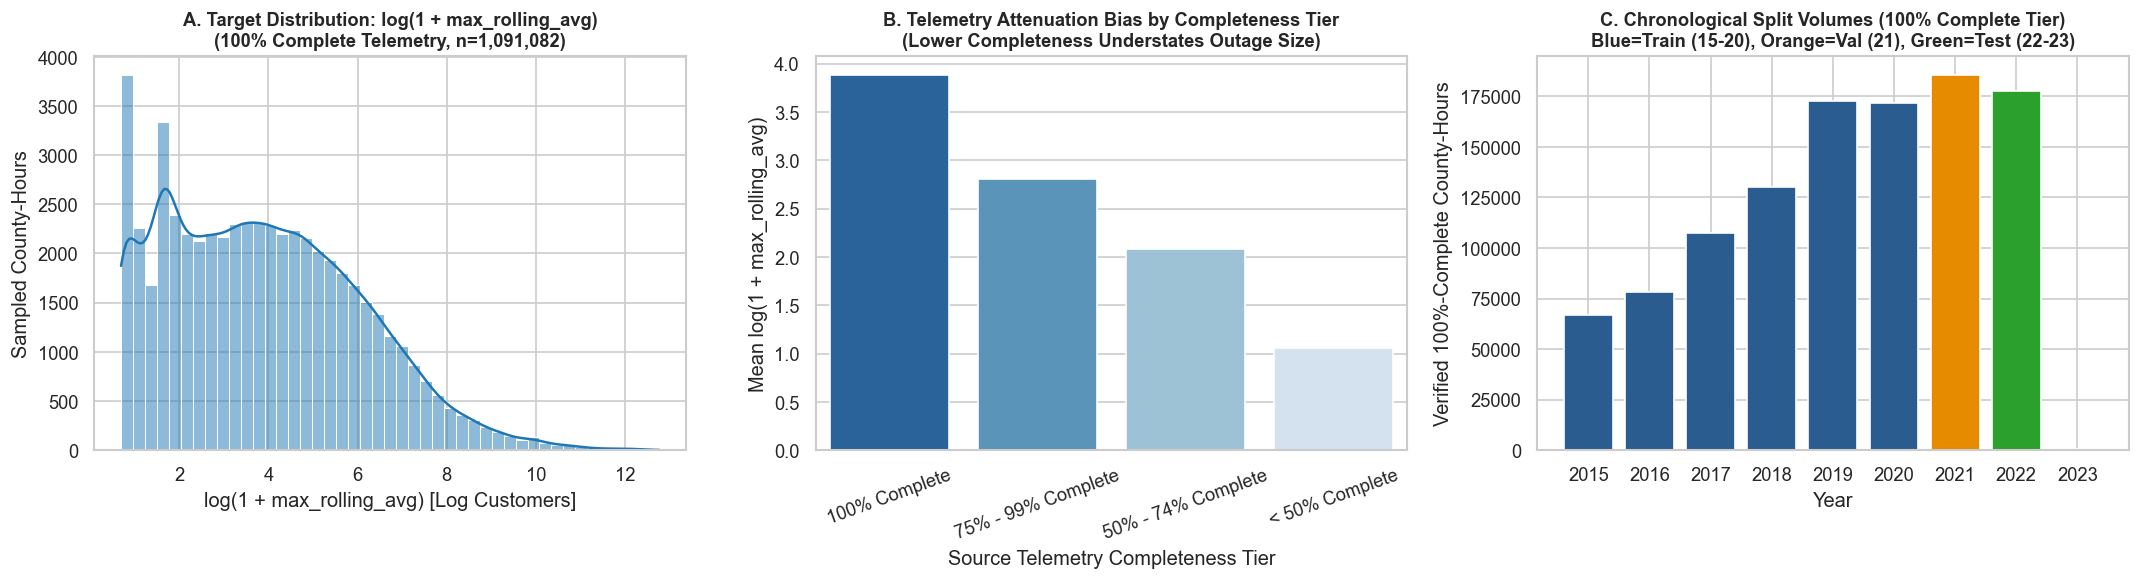

Saved EDA plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\regression_eda_overview.png


In [4]:
df_outage = df_outage.withColumn(
    "log_max_rolling_avg", F.log1p(F.col("max_rolling_avg"))
).withColumn(
    "completeness_tier",
    F.when(F.col("source_completeness_pct") == 100.0, "100% Complete")
     .when(F.col("source_completeness_pct") >= 75.0, "75% - 99% Complete")
     .when(F.col("source_completeness_pct") >= 50.0, "50% - 74% Complete")
     .otherwise("< 50% Complete")
)

tier_stats_pd = (
    df_outage.groupBy("completeness_tier")
    .agg(
        F.count("*").alias("row_count"),
        F.round(F.avg("max_rolling_avg"), 2).alias("mean_outage"),
        F.round(F.percentile_approx("max_rolling_avg", 0.5), 4).alias("median_outage"),
        F.round(F.percentile_approx("max_rolling_avg", 0.9), 2).alias("p90_outage"),
        F.round(F.avg("log_max_rolling_avg"), 4).alias("mean_log_outage"),
        F.round(F.stddev("log_max_rolling_avg"), 4).alias("std_log_outage"),
    )
    .orderBy(F.desc("mean_log_outage"))
    .toPandas()
)
print("=== Outage Distribution by Telemetry Completeness Tier ===")
print(tier_stats_pd.to_string(index=False))

yearly_stats_pd = (
    df_outage.groupBy("year")
    .agg(
        F.count("*").alias("total_hours"),
        F.sum(F.when(F.col("source_completeness_pct") == 100.0, 1).otherwise(0)).alias("complete_100_hours"),
        F.round(F.avg("log_max_rolling_avg"), 4).alias("mean_log_outage_all"),
        F.round(
            F.avg(F.when(F.col("source_completeness_pct") == 100.0, F.col("log_max_rolling_avg"))), 4
        ).alias("mean_log_outage_100pct"),
    )
    .orderBy("year")
    .toPandas()
)
print("\n=== Chronological Distribution by Year (2015-2023) ===")
print(yearly_stats_pd.to_string(index=False))

top_hazards_pd = (
    df_outage.filter(F.col("source_completeness_pct") == 100.0)
    .groupBy("Matched_Events")
    .agg(
        F.count("*").alias("hour_count"),
        F.round(F.avg("max_rolling_avg"), 2).alias("mean_outage"),
        F.round(F.avg("log_max_rolling_avg"), 4).alias("mean_log_outage"),
    )
    .orderBy(F.desc("hour_count"))
    .limit(10)
    .toPandas()
)
print("\n=== Top 10 VTEC Weather Regimes (100% Complete Telemetry Tier) ===")
print(top_hazards_pd.to_string(index=False))

sample_eda_pd = (
    df_outage.filter(F.col("source_completeness_pct") == 100.0)
    .select("max_rolling_avg", "log_max_rolling_avg")
    .sample(withReplacement=False, fraction=0.05, seed=RANDOM_SEED)
    .toPandas()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(sample_eda_pd["log_max_rolling_avg"], bins=45, kde=True, color="#1f77b4", ax=axes[0])
axes[0].set_title("A. Target Distribution: log(1 + max_rolling_avg)\n(100% Complete Telemetry, n=1,091,082)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("log(1 + max_rolling_avg) [Log Customers]")
axes[0].set_ylabel("Sampled County-Hours")

tier_order = ["100% Complete", "75% - 99% Complete", "50% - 74% Complete", "< 50% Complete"]
tier_plot_df = tier_stats_pd.set_index("completeness_tier").loc[tier_order].reset_index()
sns.barplot(data=tier_plot_df, x="completeness_tier", y="mean_log_outage", palette="Blues_r", ax=axes[1])
axes[1].set_title("B. Telemetry Attenuation Bias by Completeness Tier\n(Lower Completeness Understates Outage Size)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Source Telemetry Completeness Tier")
axes[1].set_ylabel("Mean log(1 + max_rolling_avg)")
axes[1].tick_params(axis="x", rotation=20)

split_colors = ["#2b5c8f" if y <= 2020 else ("#e68a00" if y == 2021 else "#2ca02c") for y in yearly_stats_pd["year"]]
axes[2].bar(yearly_stats_pd["year"].astype(str), yearly_stats_pd["complete_100_hours"], color=split_colors)
axes[2].set_title("C. Chronological Split Volumes (100% Complete Tier)\nBlue=Train (15-20), Orange=Val (21), Green=Test (22-23)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Verified 100%-Complete County-Hours")

plt.tight_layout()
eda_fig_path = OUTPUT_DIR / "regression_eda_overview.png"
plt.savefig(eda_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved EDA plot to: {eda_fig_path}")

## 7. Feature Engineering and Preprocessing

### 7.1 Target Variable and Observational Unit
- **Observational Unit:** Verified $100\%$-complete continuation county-hours (`source_completeness_pct == 100.0` and `hours_into_event >= 1`, $N = 843,512$ rows).
- **Target (`label_reg`):** $y_{i,t} = \log(1 + \text{max\_rolling\_avg}_{i,t})$.

### 7.2 Preventing Target and Temporal Leakage
1. **Dropping Event-Summary Columns:** Columns like `Max_outage`, `evDur_Hr`, `evDur_day`, `event_mean_completeness_pct`, and `event_min_completeness_pct` are calculated across the entire outage event (including future hours after hour $t$). These columns are removed before building features.
2. **Lag Features Within Each Event:** Using a window partitioned by `(fips_code, new_event_no)` and ordered by `event_ts`, we compute:
   - `log_lag1_outage`: $\log(1 + \text{max\_rolling\_avg}_{i, t-1})$ from the previous hour.
   - `log_lag2_outage`: $\log(1 + \text{max\_rolling\_avg}_{i, t-2})$ from two hours prior.
   - `log_onset_outage`: $\log(1 + \text{max\_rolling\_avg}_{i, t_0})$ from the initial hour of the event.
   - `lag1_minus_onset`: Outage momentum ($\text{log\_lag1\_outage} - \text{log\_lag2\_outage}$).
   - `hours_into_event`: Hours elapsed since the event started ($h \ge 1$).
3. **Historical Baselines From Training Data Only (2015-2020):** WFO warning area statistics (`wfo_log_median_area_km2`, `wfo_warning_sig_share`, `wfo_polygon_share`) and county mean outage levels (`county_train_mean_log_outage`) are aggregated using only 2015-2020 records.
4. **Chronological Split:**
   - **Train (2015-2020):** $560,572$ rows ($66.46\%$)
   - **Validation (2021):** $146,995$ rows ($17.43\%$)
   - **Test (2022-2023):** $135,945$ rows ($16.12\%$)
   - All Spark ML preprocessing stages (`Imputer`, `StringIndexer`, `OneHotEncoder`, `StandardScaler`) are fitted only on the training set.

In [5]:
event_win = Window.partitionBy("fips_code", "new_event_no").orderBy("event_ts")

df_lagged = (
    df_outage
    .withColumn("hours_into_event", (F.row_number().over(event_win) - F.lit(1)).cast("double"))
    .withColumn("is_onset_hour", F.when(F.col("hours_into_event") == 0.0, 1.0).otherwise(0.0))
    .withColumn("lag1_outage", F.coalesce(F.lag("max_rolling_avg", 1).over(event_win), F.lit(0.0)))
    .withColumn("lag2_outage", F.coalesce(F.lag("max_rolling_avg", 2).over(event_win), F.lit(0.0)))
    .withColumn(
        "prior_onset_outage",
        F.when(F.col("hours_into_event") >= 1.0, F.first("max_rolling_avg").over(event_win)).otherwise(F.lit(0.0))
    )
    .withColumn("log_lag1_outage", F.log1p(F.col("lag1_outage")))
    .withColumn("log_lag2_outage", F.log1p(F.col("lag2_outage")))
    .withColumn("log_onset_outage", F.log1p(F.col("prior_onset_outage")))
    .withColumn("lag1_minus_onset", F.col("log_lag1_outage") - F.col("log_lag2_outage"))
    .withColumn("log_median_sum", F.log1p(F.col("median_sum")))
    .withColumn("hour_sin", F.sin(2.0 * np.pi * F.col("hour_of_day") / 24.0))
    .withColumn("hour_cos", F.cos(2.0 * np.pi * F.col("hour_of_day") / 24.0))
    .withColumn("month_sin", F.sin(2.0 * np.pi * F.col("month") / 12.0))
    .withColumn("month_cos", F.cos(2.0 * np.pi * F.col("month") / 12.0))
    .withColumn("primary_phenom", F.split(F.col("Matched_Events"), "; ").getItem(0))
    .withColumn("is_convective", F.when(F.col("Matched_Events").rlike("SV|TO"), 1.0).otherwise(0.0))
    .withColumn("is_winter", F.when(F.col("Matched_Events").rlike("WS|WW|BZ|IS|LE"), 1.0).otherwise(0.0))
    .withColumn("is_heat", F.when(F.col("Matched_Events").rlike("HT|EH"), 1.0).otherwise(0.0))
    .withColumn("is_wind_tropical", F.when(F.col("Matched_Events").rlike("WI|HW|HU|TR|SS"), 1.0).otherwise(0.0))
    .withColumn("is_flood", F.when(F.col("Matched_Events").rlike("FA|FL|FF"), 1.0).otherwise(0.0))
    .withColumn("matched_count_dbl", F.col("Matched_Count").cast("double"))
)

df_nws_parsed = df_nws_raw.withColumn(
    "nws_year", F.regexp_extract(F.col("ISSUED"), r"(\d{4})", 1).cast("int")
)

wfo_train_priors = (
    df_nws_parsed.filter((F.col("nws_year") >= 2015) & (F.col("nws_year") <= 2020))
    .groupBy("WFO")
    .agg(
        F.log1p(F.percentile_approx("AREA_KM2", 0.5)).alias("wfo_log_median_area_km2"),
        F.avg(F.when(F.col("SIG") == "W", 1.0).otherwise(0.0)).alias("wfo_warning_sig_share"),
        F.avg(F.when(F.col("GTYPE") == "P", 1.0).otherwise(0.0)).alias("wfo_polygon_share"),
    )
)

LEAKAGE_COLS = [
    "Max_outage",
    "evDur_Hr",
    "evDur_day",
    "event_mean_completeness_pct",
    "event_min_completeness_pct",
]

df_model_base = (
    df_lagged.filter((F.col("source_completeness_pct") == 100.0) & (F.col("hours_into_event") >= 1.0))
    .drop(*LEAKAGE_COLS)
    .join(wfo_train_priors, on="WFO", how="left")
    .withColumnRenamed("log_max_rolling_avg", "label_reg")
)

county_train_priors = (
    df_model_base.filter(F.col("year") <= 2020)
    .groupBy("fips_code")
    .agg(F.avg("label_reg").alias("county_train_mean_log_outage"))
)

df_model_full = df_model_base.join(county_train_priors, on="fips_code", how="left")

def save_and_verify_parquet(spark_df, parquet_path: Path, sample_limit: int = None):
    target_df = spark_df.limit(sample_limit) if sample_limit else spark_df
    try:
        target_df.write.mode("overwrite").parquet(str(parquet_path))
        mode_used = "Spark Native Parquet Writer"
    except Exception:
        if parquet_path.exists() and parquet_path.is_dir():
            import shutil
            shutil.rmtree(parquet_path, ignore_errors=True)
        pdf = target_df.toPandas()
        pq.write_table(pa.Table.from_pandas(pdf, preserve_index=False), str(parquet_path))
        mode_used = "PyArrow Columnar Parquet Writer (Windows Hadoop-less fallback)"
    verified_count = spark.read.parquet(str(parquet_path)).count()
    print(f"Persisted & verified Parquet at {parquet_path.name} ({verified_count:,d} rows via {mode_used})")

parquet_checkpoint_path = OUTPUT_DIR / "regression_processed_features.parquet"
save_and_verify_parquet(
    df_model_full.select(
        "fips_code", "Hour", "year", "state", "WFO", "primary_phenom",
        "label_reg", "max_rolling_avg", "log_lag1_outage", "log_onset_outage",
        "hours_into_event", "is_onset_hour", "lag1_minus_onset", "log_median_sum",
        "county_train_mean_log_outage", "matched_count_dbl", "is_convective",
        "is_winter", "is_heat", "is_wind_tropical", "is_flood",
        "hour_sin", "hour_cos", "month_sin", "month_cos",
        "wfo_log_median_area_km2", "wfo_warning_sig_share", "wfo_polygon_share"
    ),
    parquet_checkpoint_path,
)

train_df = df_model_full.filter(F.col("year") <= 2020).cache()
val_df = df_model_full.filter(F.col("year") == 2021).cache()
test_df = df_model_full.filter(F.col("year") >= 2022).cache()

n_train, n_val, n_test = train_df.count(), val_df.count(), test_df.count()
print(f"\n=== Chronological Split Verification ===")
print(f"Train (2015-2020) : {n_train:>9,d} rows ({n_train / (n_train+n_val+n_test)*100:.2f}%)")
print(f"Val   (2021)      : {n_val:>9,d} rows ({n_val / (n_train+n_val+n_test)*100:.2f}%)")
print(f"Test  (2022-2023) : {n_test:>9,d} rows ({n_test / (n_train+n_val+n_test)*100:.2f}%)")

NUM_FEATURES = [
    "log_lag1_outage",
    "log_onset_outage",
    "hours_into_event",
    "is_onset_hour",
    "lag1_minus_onset",
    "log_median_sum",
    "county_train_mean_log_outage",
    "matched_count_dbl",
    "is_convective",
    "is_winter",
    "is_heat",
    "is_wind_tropical",
    "is_flood",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "wfo_log_median_area_km2",
    "wfo_warning_sig_share",
    "wfo_polygon_share",
]
IMPUTED_FEATURES = [f"{c}_imp" for c in NUM_FEATURES]
CAT_FEATURES = ["primary_phenom", "state"]
INDEXED_CATS = [f"{c}_idx" for c in CAT_FEATURES]
OHE_CATS = [f"{c}_ohe" for c in CAT_FEATURES]

imputer = Imputer(strategy="median", inputCols=NUM_FEATURES, outputCols=IMPUTED_FEATURES)
indexers = [
    StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
    for c in CAT_FEATURES
]
encoder = OneHotEncoder(inputCols=INDEXED_CATS, outputCols=OHE_CATS, handleInvalid="keep")

tree_assembler = VectorAssembler(
    inputCols=IMPUTED_FEATURES + OHE_CATS,
    outputCol="tree_features",
    handleInvalid="keep",
)
scaler = StandardScaler(
    inputCol="tree_features",
    outputCol="scaled_features",
    withMean=False,
    withStd=True,
)

prep_pipeline = Pipeline(stages=[imputer] + indexers + [encoder, tree_assembler, scaler])
t0 = time.time()
prep_model = prep_pipeline.fit(train_df)
train_prep = prep_model.transform(train_df).select("fips_code", "Hour", "year", "is_onset_hour", "hours_into_event", "primary_phenom", "label_reg", "tree_features", "scaled_features").cache()
val_prep = prep_model.transform(val_df).select("fips_code", "Hour", "year", "is_onset_hour", "hours_into_event", "primary_phenom", "label_reg", "tree_features", "scaled_features").cache()
test_prep = prep_model.transform(test_df).select("fips_code", "Hour", "year", "is_onset_hour", "hours_into_event", "primary_phenom", "label_reg", "tree_features", "scaled_features").cache()

_ = train_prep.count()
_ = val_prep.count()
_ = test_prep.count()
train_df.unpersist()
val_df.unpersist()
test_df.unpersist()
print(f"Preprocessing pipeline fitted on Train and applied to Val/Test in {time.time() - t0:.2f}s.")

Persisted & verified Parquet at regression_processed_features.parquet (843,512 rows via PyArrow Columnar Parquet Writer (Windows Hadoop-less fallback))



=== Chronological Split Verification ===
Train (2015-2020) :   560,572 rows (66.46%)
Val   (2021)      :   146,995 rows (17.43%)
Test  (2022-2023) :   135,945 rows (16.12%)


Preprocessing pipeline fitted on Train and applied to Val/Test in 10.39s.


## 8. Model 1: Linear Regression (`Spark MLlib`)

Spark MLlib's `LinearRegression` fits a regularized linear model minimizing squared error with ElasticNet (L1/L2) regularization:
$$\min_{\mathbf{w}, b} \frac{1}{2N} \sum_{i=1}^{N} \left( \mathbf{w}^\top \mathbf{x}_i + b - y_i \right)^2 + \lambda \left( \alpha \|\mathbf{w}\|_1 + \frac{1-\alpha}{2} \|\mathbf{w}\|_2^2 \right)$$
We test combinations of `regParam` ($\lambda \in \{0.0001, 0.001, 0.01\}$) and `elasticNetParam` ($\alpha \in \{0.0, 0.5\}$) on the **2021 Validation set**, select the best configuration by validation RMSE, and evaluate it on the **2022-2023 Test set** using **MAE**, **RMSE**, and **$R^2$**.

In [6]:
eval_mae = RegressionEvaluator(labelCol="label_reg", predictionCol="prediction", metricName="mae")
eval_rmse = RegressionEvaluator(labelCol="label_reg", predictionCol="prediction", metricName="rmse")
eval_r2 = RegressionEvaluator(labelCol="label_reg", predictionCol="prediction", metricName="r2")

def evaluate_regression_predictions(pred_df, split_name: str, model_name: str):
    mae = eval_mae.evaluate(pred_df)
    rmse = eval_rmse.evaluate(pred_df)
    r2 = eval_r2.evaluate(pred_df)
    return {
        "Model": model_name,
        "Split": split_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4),
    }

lr_grid = [
    {"regParam": 0.0001, "elasticNetParam": 0.0},
    {"regParam": 0.001, "elasticNetParam": 0.0},
    {"regParam": 0.001, "elasticNetParam": 0.5},
    {"regParam": 0.01, "elasticNetParam": 0.5},
]

best_lr_val_rmse = float("inf")
best_lr_model = None
best_lr_params = None
lr_tuning_records = []

for params in lr_grid:
    t_start = time.time()
    lr_est = LinearRegression(
        featuresCol="scaled_features",
        labelCol="label_reg",
        regParam=params["regParam"],
        elasticNetParam=params["elasticNetParam"],
        maxIter=100,
    )
    model_cand = lr_est.fit(train_prep)
    val_preds = model_cand.transform(val_prep)
    val_rmse = eval_rmse.evaluate(val_preds)
    val_mae = eval_mae.evaluate(val_preds)
    val_r2 = eval_r2.evaluate(val_preds)
    elapsed = time.time() - t_start
    lr_tuning_records.append({
        "regParam": params["regParam"],
        "elasticNetParam": params["elasticNetParam"],
        "Val_MAE": round(val_mae, 4),
        "Val_RMSE": round(val_rmse, 4),
        "Val_R2": round(val_r2, 4),
        "Train_Time_s": round(elapsed, 2),
    })
    if val_rmse < best_lr_val_rmse:
        best_lr_val_rmse = val_rmse
        best_lr_model = model_cand
        best_lr_params = params

print("=== Linear Regression Validation Tuning Results (2021 Split) ===")
print(pd.DataFrame(lr_tuning_records).to_string(index=False))
print(f"\nSelected Best Linear Regression Params: {best_lr_params}")

lr_train_metrics = evaluate_regression_predictions(best_lr_model.transform(train_prep), "Train (2015-2020)", "Linear Regression")
lr_val_metrics = evaluate_regression_predictions(best_lr_model.transform(val_prep), "Validation (2021)", "Linear Regression")
lr_test_preds = best_lr_model.transform(test_prep).cache()
lr_test_metrics = evaluate_regression_predictions(lr_test_preds, "Test (2022-2023)", "Linear Regression")

print("\n=== Linear Regression Final Evaluation Metrics ===")
print(pd.DataFrame([lr_train_metrics, lr_val_metrics, lr_test_metrics]).to_string(index=False))

=== Linear Regression Validation Tuning Results (2021 Split) ===
 regParam  elasticNetParam  Val_MAE  Val_RMSE  Val_R2  Train_Time_s
   0.0001              0.0   0.3330    0.5580  0.9503          3.37
   0.0010              0.0   0.3332    0.5580  0.9503          2.21
   0.0010              0.5   0.3325    0.5576  0.9503          3.75
   0.0100              0.5   0.3299    0.5552  0.9507          2.19

Selected Best Linear Regression Params: {'regParam': 0.01, 'elasticNetParam': 0.5}



=== Linear Regression Final Evaluation Metrics ===
            Model             Split    MAE   RMSE     R2
Linear Regression Train (2015-2020) 0.3311 0.5762 0.9283
Linear Regression Validation (2021) 0.3299 0.5552 0.9507
Linear Regression  Test (2022-2023) 0.3212 0.5575 0.9267


## 9. Model 2: Random Forest Regressor (`Spark MLlib`)

`RandomForestRegressor` trains an ensemble of decision trees in parallel on bootstrap samples of the training data, averaging the predictions of all trees:
$$\hat{y}_{\text{RF}}(\mathbf{x}) = \frac{1}{M} \sum_{m=1}^{M} \hat{f}_m(\mathbf{x})$$
Unlike a linear model, Random Forest can capture non-linear interactions between prior-hour outage size (`log_lag1_outage`), recent outage change (`lag1_minus_onset`), elapsed event duration (`hours_into_event`), and county baseline levels.

In [7]:
rf_grid = [
    {"numTrees": 30, "maxDepth": 8},
    {"numTrees": 30, "maxDepth": 10},
]

best_rf_val_rmse = float("inf")
best_rf_model = None
best_rf_params = None
rf_tuning_records = []

for params in rf_grid:
    t_start = time.time()
    rf_est = RandomForestRegressor(
        featuresCol="tree_features",
        labelCol="label_reg",
        numTrees=params["numTrees"],
        maxDepth=params["maxDepth"],
        subsamplingRate=0.8,
        featureSubsetStrategy="onethird",
        seed=RANDOM_SEED,
    )
    model_cand = rf_est.fit(train_prep)
    val_preds = model_cand.transform(val_prep)
    val_rmse = eval_rmse.evaluate(val_preds)
    val_mae = eval_mae.evaluate(val_preds)
    val_r2 = eval_r2.evaluate(val_preds)
    elapsed = time.time() - t_start
    rf_tuning_records.append({
        "numTrees": params["numTrees"],
        "maxDepth": params["maxDepth"],
        "Val_MAE": round(val_mae, 4),
        "Val_RMSE": round(val_rmse, 4),
        "Val_R2": round(val_r2, 4),
        "Train_Time_s": round(elapsed, 2),
    })
    if val_rmse < best_rf_val_rmse:
        best_rf_val_rmse = val_rmse
        best_rf_model = model_cand
        best_rf_params = params

print("=== Random Forest Regressor Validation Tuning Results (2021 Split) ===")
print(pd.DataFrame(rf_tuning_records).to_string(index=False))
print(f"\nSelected Best Random Forest Params: {best_rf_params}")

rf_train_metrics = evaluate_regression_predictions(best_rf_model.transform(train_prep), "Train (2015-2020)", "Random Forest Regressor")
rf_val_metrics = evaluate_regression_predictions(best_rf_model.transform(val_prep), "Validation (2021)", "Random Forest Regressor")
rf_test_preds = best_rf_model.transform(test_prep).cache()
rf_test_metrics = evaluate_regression_predictions(rf_test_preds, "Test (2022-2023)", "Random Forest Regressor")

print("\n=== Random Forest Regressor Final Evaluation Metrics ===")
print(pd.DataFrame([rf_train_metrics, rf_val_metrics, rf_test_metrics]).to_string(index=False))

=== Random Forest Regressor Validation Tuning Results (2021 Split) ===
 numTrees  maxDepth  Val_MAE  Val_RMSE  Val_R2  Train_Time_s
       30         8   0.4273    0.6915  0.9236         18.30
       30        10   0.3685    0.6243  0.9377         27.21

Selected Best Random Forest Params: {'numTrees': 30, 'maxDepth': 10}



=== Random Forest Regressor Final Evaluation Metrics ===
                  Model             Split    MAE   RMSE     R2
Random Forest Regressor Train (2015-2020) 0.3238 0.5573 0.9329
Random Forest Regressor Validation (2021) 0.3685 0.6243 0.9377
Random Forest Regressor  Test (2022-2023) 0.3176 0.5474 0.9293


## 10. Model 3: Gradient-Boosted Tree Regressor (`Spark MLlib GBTRegressor`)

While Random Forest builds independent trees in parallel to reduce variance, `GBTRegressor` trains shallow regression trees **sequentially** using stagewise additive gradient boosting:
$$\hat{y}_{\text{GBT}}^{(m)}(\mathbf{x}) = \hat{y}_{\text{GBT}}^{(m-1)}(\mathbf{x}) + \eta \, h_m(\mathbf{x})$$
where each new tree $h_m(\mathbf{x})$ is fitted to the negative gradient (residual error $y_i - \hat{y}^{(m-1)}(\mathbf{x}_i)$) of the squared-error loss function with learning rate (`stepSize`) $\eta$. By focusing each successive tree on hard-to-predict storm hours, `GBTRegressor` reduces both bias and residual error.

In [8]:
gbt_grid = [
    {"maxIter": 25, "maxDepth": 5, "stepSize": 0.1},
    {"maxIter": 35, "maxDepth": 6, "stepSize": 0.1},
]

best_gbt_val_rmse = float("inf")
best_gbt_model = None
best_gbt_params = None
gbt_tuning_records = []

for params in gbt_grid:
    t_start = time.time()
    gbt_est = GBTRegressor(
        featuresCol="tree_features",
        labelCol="label_reg",
        maxIter=params["maxIter"],
        maxDepth=params["maxDepth"],
        stepSize=params["stepSize"],
        subsamplingRate=0.8,
        seed=RANDOM_SEED,
    )
    model_cand = gbt_est.fit(train_prep)
    val_preds = model_cand.transform(val_prep)
    val_rmse = eval_rmse.evaluate(val_preds)
    val_mae = eval_mae.evaluate(val_preds)
    val_r2 = eval_r2.evaluate(val_preds)
    elapsed = time.time() - t_start
    gbt_tuning_records.append({
        "maxIter": params["maxIter"],
        "maxDepth": params["maxDepth"],
        "stepSize": params["stepSize"],
        "Val_MAE": round(val_mae, 4),
        "Val_RMSE": round(val_rmse, 4),
        "Val_R2": round(val_r2, 4),
        "Train_Time_s": round(elapsed, 2),
    })
    if val_rmse < best_gbt_val_rmse:
        best_gbt_val_rmse = val_rmse
        best_gbt_model = model_cand
        best_gbt_params = params

print("=== Gradient-Boosted Tree Regressor Validation Tuning Results (2021 Split) ===")
print(pd.DataFrame(gbt_tuning_records).to_string(index=False))
print(f"\nSelected Best GBTRegressor Params: {best_gbt_params}")

gbt_train_metrics = evaluate_regression_predictions(best_gbt_model.transform(train_prep), "Train (2015-2020)", "GBT Regressor")
gbt_val_metrics = evaluate_regression_predictions(best_gbt_model.transform(val_prep), "Validation (2021)", "GBT Regressor")
gbt_test_preds = best_gbt_model.transform(test_prep).cache()
gbt_test_metrics = evaluate_regression_predictions(gbt_test_preds, "Test (2022-2023)", "GBT Regressor")

print("\n=== GBT Regressor Final Evaluation Metrics ===")
print(pd.DataFrame([gbt_train_metrics, gbt_val_metrics, gbt_test_metrics]).to_string(index=False))

=== Gradient-Boosted Tree Regressor Validation Tuning Results (2021 Split) ===
 maxIter  maxDepth  stepSize  Val_MAE  Val_RMSE  Val_R2  Train_Time_s
      25         5       0.1   0.3410    0.5912  0.9442         23.69
      35         6       0.1   0.3279    0.5817  0.9459         37.05

Selected Best GBTRegressor Params: {'maxIter': 35, 'maxDepth': 6, 'stepSize': 0.1}



=== GBT Regressor Final Evaluation Metrics ===
        Model             Split    MAE   RMSE     R2
GBT Regressor Train (2015-2020) 0.3046 0.5445 0.9360
GBT Regressor Validation (2021) 0.3279 0.5817 0.9459
GBT Regressor  Test (2022-2023) 0.2947 0.5324 0.9332


## 11. Model Comparison and Residual Analysis

We compare **Linear Regression**, **Random Forest Regressor**, and **Gradient-Boosted Tree Regressor (`GBTRegressor`)** on the **2022-2023 Test Set ($135,945$ county-hours)** across overall test metrics (**MAE**, **RMSE**, **$R^2$**) and across early propagation hours ($1 \le h \le 3$) vs. sustained outage hours ($h \ge 4$).

=== Master 3-Model Regression Comparison Table ===
                  Model             Split    MAE   RMSE     R2
      Linear Regression Train (2015-2020) 0.3311 0.5762 0.9283
      Linear Regression Validation (2021) 0.3299 0.5552 0.9507
      Linear Regression  Test (2022-2023) 0.3212 0.5575 0.9267
Random Forest Regressor Train (2015-2020) 0.3238 0.5573 0.9329
Random Forest Regressor Validation (2021) 0.3685 0.6243 0.9377
Random Forest Regressor  Test (2022-2023) 0.3176 0.5474 0.9293
          GBT Regressor Train (2015-2020) 0.3046 0.5445 0.9360
          GBT Regressor Validation (2021) 0.3279 0.5817 0.9459
          GBT Regressor  Test (2022-2023) 0.2947 0.5324 0.9332



=== Test Set Error Breakdown by Event Regime (2022-2023) ===
                     Regime                   Model  Test_Rows    MAE   RMSE     R2
Early Propagation (1<=h<=3)       Linear Regression      53818 0.3936 0.6667 0.8748
Early Propagation (1<=h<=3) Random Forest Regressor      53818 0.3778 0.6377 0.8854
Early Propagation (1<=h<=3)           GBT Regressor      53818 0.3598 0.6274 0.8891
     Sustained Event (h>=4)       Linear Regression      82127 0.2737 0.4725 0.9487
     Sustained Event (h>=4) Random Forest Regressor      82127 0.2781 0.4790 0.9473
     Sustained Event (h>=4)           GBT Regressor      82127 0.2520 0.4595 0.9515

=== Top 10 Numeric Features in Tree Ensemble Regressors ===
                     Feature  RF_Importance  GBT_Importance
             log_lag1_outage         0.8045          0.9026
            log_onset_outage         0.0575          0.0045
county_train_mean_log_outage         0.0508          0.0078
            hours_into_event         0.0354      

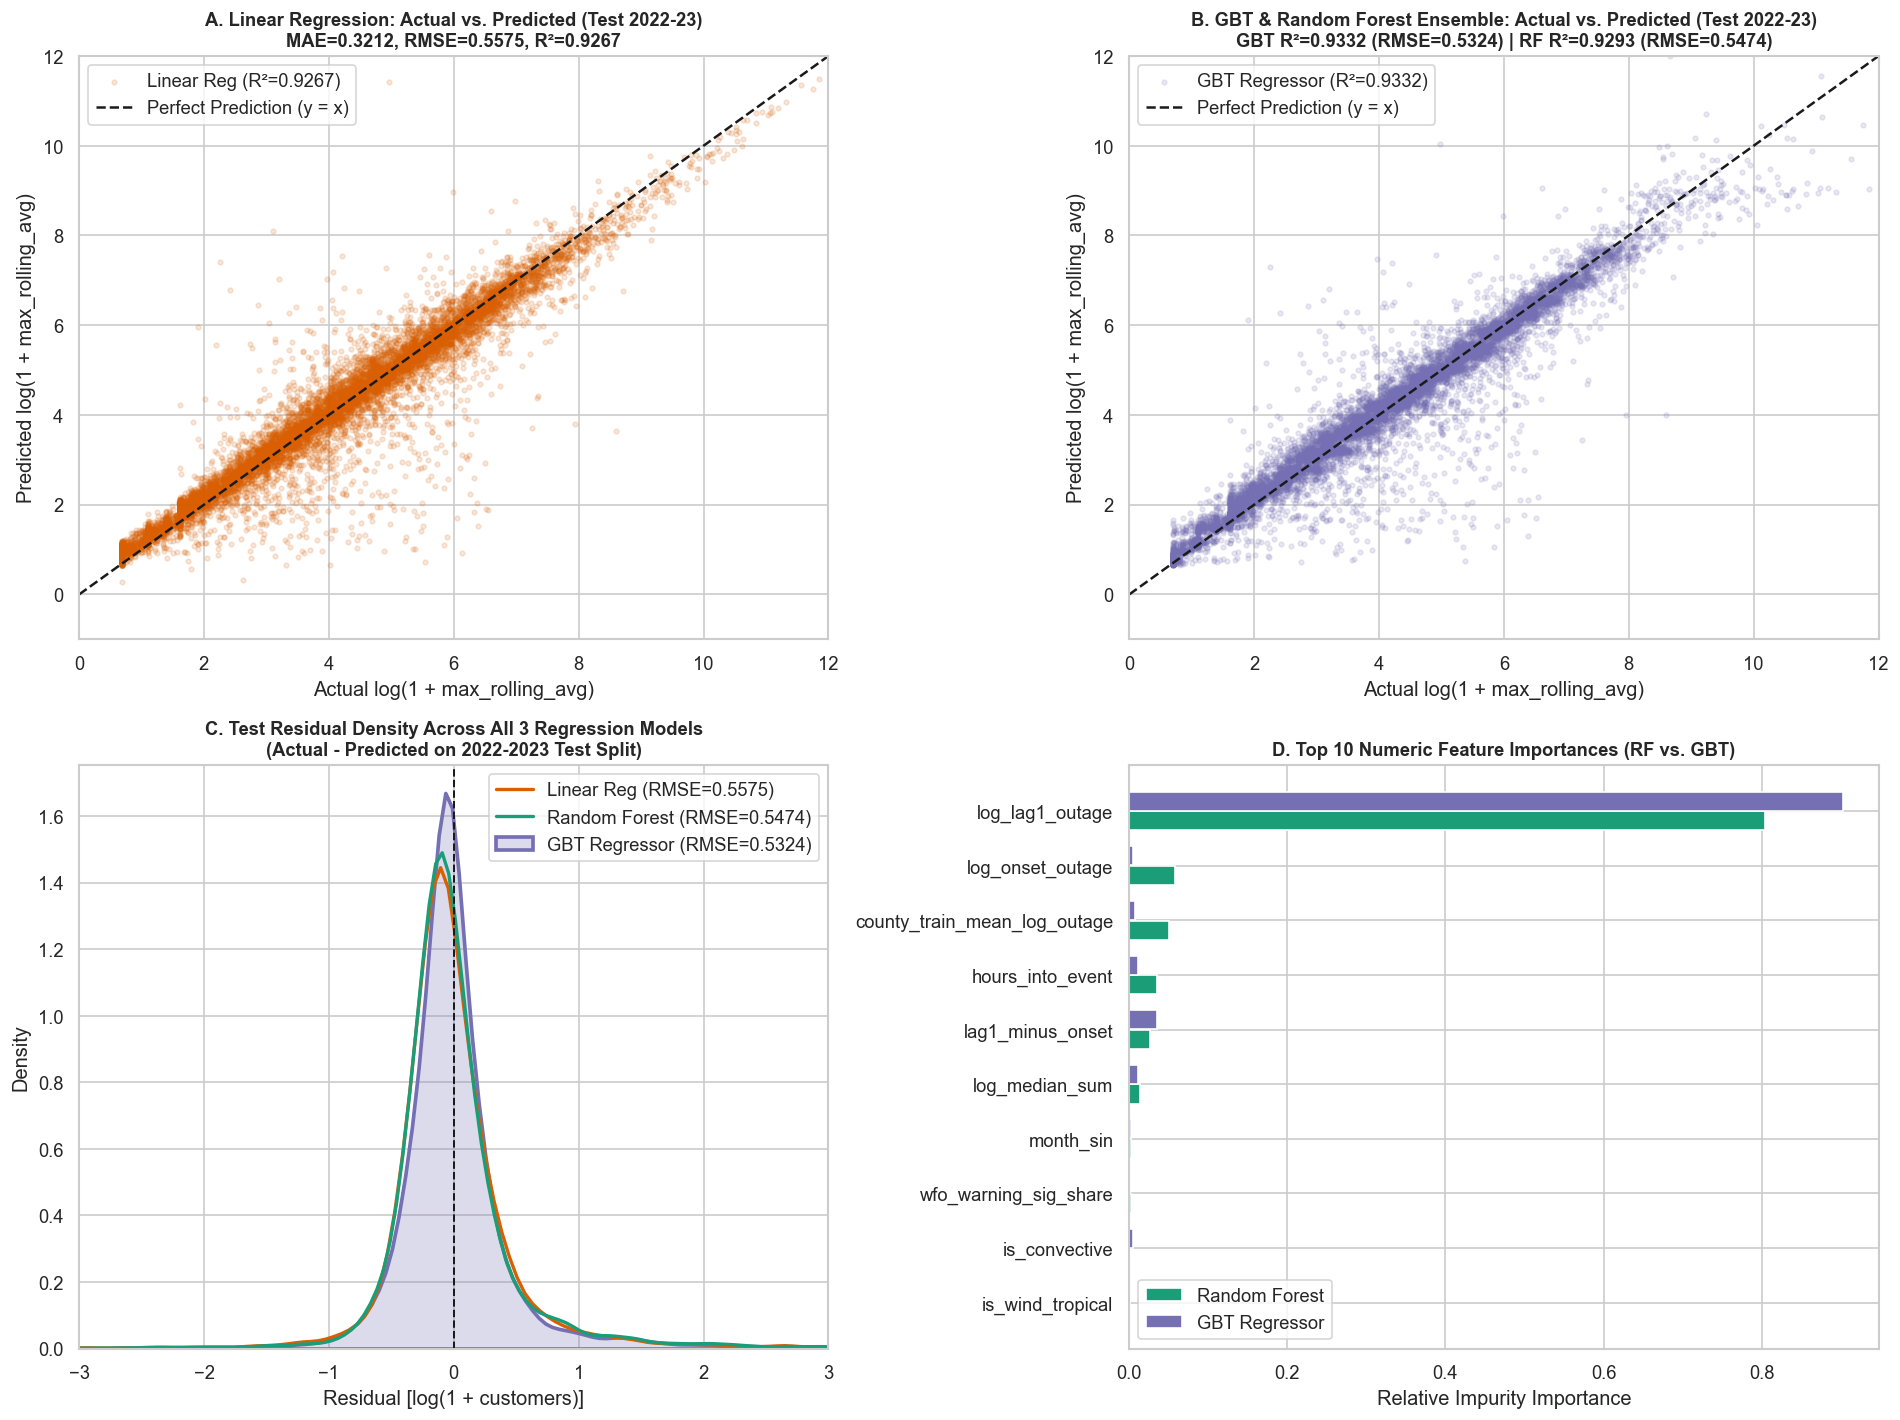

Saved diagnostic plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\regression_evaluation_diagnostics.png


In [9]:
comparison_df = pd.DataFrame([
    lr_train_metrics, lr_val_metrics, lr_test_metrics,
    rf_train_metrics, rf_val_metrics, rf_test_metrics,
    gbt_train_metrics, gbt_val_metrics, gbt_test_metrics,
])
comp_csv_path = OUTPUT_DIR / "regression_metrics_comparison.csv"
comparison_df.to_csv(comp_csv_path, index=False)
print("=== Master 3-Model Regression Comparison Table ===")
print(comparison_df.to_string(index=False))

regime_rows = []
for regime_label, cond in [("Early Propagation (1<=h<=3)", F.col("hours_into_event") <= 3.0), ("Sustained Event (h>=4)", F.col("hours_into_event") >= 4.0)]:
    for m_name, p_df in [
        ("Linear Regression", lr_test_preds),
        ("Random Forest Regressor", rf_test_preds),
        ("GBT Regressor", gbt_test_preds),
    ]:
        sub_df = p_df.filter(cond)
        regime_rows.append({
            "Regime": regime_label,
            "Model": m_name,
            "Test_Rows": sub_df.count(),
            "MAE": round(eval_mae.evaluate(sub_df), 4),
            "RMSE": round(eval_rmse.evaluate(sub_df), 4),
            "R2": round(eval_r2.evaluate(sub_df), 4),
        })
regime_comp_df = pd.DataFrame(regime_rows)
regime_csv_path = OUTPUT_DIR / "regression_regime_error_breakdown.csv"
regime_comp_df.to_csv(regime_csv_path, index=False)
print("\n=== Test Set Error Breakdown by Event Regime (2022-2023) ===")
print(regime_comp_df.to_string(index=False))

rf_importances = best_rf_model.featureImportances.toArray()[:len(IMPUTED_FEATURES)]
gbt_importances = best_gbt_model.featureImportances.toArray()[:len(IMPUTED_FEATURES)]
feat_imp_df = pd.DataFrame({
    "Feature": NUM_FEATURES,
    "RF_Importance": np.round(rf_importances, 4),
    "GBT_Importance": np.round(gbt_importances, 4),
}).sort_values("RF_Importance", ascending=False)
feat_imp_df.to_csv(OUTPUT_DIR / "regression_rf_feature_importances.csv", index=False)
print("\n=== Top 10 Numeric Features in Tree Ensemble Regressors ===")
print(feat_imp_df.head(10).to_string(index=False))

lr_sample_pd = (
    lr_test_preds
    .withColumn("residual", F.col("label_reg") - F.col("prediction"))
    .select("label_reg", F.col("prediction").alias("lr_pred"), F.col("residual").alias("lr_res"))
    .sample(withReplacement=False, fraction=0.08, seed=RANDOM_SEED)
    .toPandas()
)
rf_sample_pd = (
    rf_test_preds
    .withColumn("residual", F.col("label_reg") - F.col("prediction"))
    .select("label_reg", F.col("prediction").alias("rf_pred"), F.col("residual").alias("rf_res"))
    .sample(withReplacement=False, fraction=0.08, seed=RANDOM_SEED)
    .toPandas()
)
gbt_sample_pd = (
    gbt_test_preds
    .withColumn("residual", F.col("label_reg") - F.col("prediction"))
    .select("label_reg", F.col("prediction").alias("gbt_pred"), F.col("residual").alias("gbt_res"))
    .sample(withReplacement=False, fraction=0.08, seed=RANDOM_SEED)
    .toPandas()
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].scatter(lr_sample_pd["label_reg"], lr_sample_pd["lr_pred"], alpha=0.15, s=8, c="#d95f02", label=f"Linear Reg (R²={lr_test_metrics['R2']:.4f})")
axes[0, 0].plot([0, 12], [0, 12], "k--", lw=1.5, label="Perfect Prediction (y = x)")
axes[0, 0].set_xlim(0, 12)
axes[0, 0].set_ylim(-1, 12)
axes[0, 0].set_title(f"A. Linear Regression: Actual vs. Predicted (Test 2022-23)\nMAE={lr_test_metrics['MAE']:.4f}, RMSE={lr_test_metrics['RMSE']:.4f}, R²={lr_test_metrics['R2']:.4f}", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Actual log(1 + max_rolling_avg)")
axes[0, 0].set_ylabel("Predicted log(1 + max_rolling_avg)")
axes[0, 0].legend()

axes[0, 1].scatter(gbt_sample_pd["label_reg"], gbt_sample_pd["gbt_pred"], alpha=0.15, s=8, c="#7570b3", label=f"GBT Regressor (R²={gbt_test_metrics['R2']:.4f})")
axes[0, 1].plot([0, 12], [0, 12], "k--", lw=1.5, label="Perfect Prediction (y = x)")
axes[0, 1].set_xlim(0, 12)
axes[0, 1].set_ylim(-1, 12)
axes[0, 1].set_title(f"B. GBT & Random Forest Ensemble: Actual vs. Predicted (Test 2022-23)\nGBT R²={gbt_test_metrics['R2']:.4f} (RMSE={gbt_test_metrics['RMSE']:.4f}) | RF R²={rf_test_metrics['R2']:.4f} (RMSE={rf_test_metrics['RMSE']:.4f})", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Actual log(1 + max_rolling_avg)")
axes[0, 1].set_ylabel("Predicted log(1 + max_rolling_avg)")
axes[0, 1].legend()

sns.kdeplot(lr_sample_pd["lr_res"], fill=False, lw=2.0, color="#d95f02", label=f"Linear Reg (RMSE={lr_test_metrics['RMSE']:.4f})", ax=axes[1, 0])
sns.kdeplot(rf_sample_pd["rf_res"], fill=False, lw=2.0, color="#1b9e77", label=f"Random Forest (RMSE={rf_test_metrics['RMSE']:.4f})", ax=axes[1, 0])
sns.kdeplot(gbt_sample_pd["gbt_res"], fill=True, alpha=0.25, lw=2.2, color="#7570b3", label=f"GBT Regressor (RMSE={gbt_test_metrics['RMSE']:.4f})", ax=axes[1, 0])
axes[1, 0].axvline(0.0, color="k", linestyle="--", lw=1.2)
axes[1, 0].set_xlim(-3.0, 3.0)
axes[1, 0].set_title("C. Test Residual Density Across All 3 Regression Models\n(Actual - Predicted on 2022-2023 Test Split)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Residual [log(1 + customers)]")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()

top10_imp = feat_imp_df.head(10).iloc[::-1]
y_idx = np.arange(len(top10_imp))
axes[1, 1].barh(y_idx - 0.18, top10_imp["RF_Importance"], height=0.35, color="#1b9e77", label="Random Forest")
axes[1, 1].barh(y_idx + 0.18, top10_imp["GBT_Importance"], height=0.35, color="#7570b3", label="GBT Regressor")
axes[1, 1].set_yticks(y_idx)
axes[1, 1].set_yticklabels(top10_imp["Feature"])
axes[1, 1].set_title("D. Top 10 Numeric Feature Importances (RF vs. GBT)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Relative Impurity Importance")
axes[1, 1].legend()

plt.tight_layout()
eval_fig_path = OUTPUT_DIR / "regression_evaluation_diagnostics.png"
plt.savefig(eval_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved diagnostic plot to: {eval_fig_path}")

## 12. Execution-Time and Scalability Analysis

To evaluate how our three PySpark regression models scale with dataset size and Spark partition parallelism, we run two experimental benchmarks:
1. **Data-Volume Scaling ($25\%, 50\%, 75\%, 100\%$ of Training Data):** We train **Linear Regression**, **Random Forest Regressor**, and **GBT Regressor** on $25\%$ ($\sim 140\text{K}$ rows), $50\%$ ($\sim 280\text{K}$ rows), $75\%$ ($\sim 420\text{K}$ rows), and $100\%$ ($560,572$ rows) of the training split and measure training + test evaluation runtime and test RMSE.
2. **Spark Partition Parallelism Scaling ($4, 8, 16$ Partitions):** We repartition the training DataFrame into $4, 8,$ and $16$ Spark partitions and compare model fitting times across all three algorithms.

=== Regression Data-Volume Scalability Benchmark (25% to 100% Training Data) ===
 Scale_Pct  Train_Rows  LR_Time_s  RF_Time_s  GBT_Time_s  LR_Test_RMSE  RF_Test_RMSE  GBT_Test_RMSE
        25      140227       1.05       4.70       13.05        0.5574        0.5823         0.5433
        50      280884       1.16       6.40       14.16        0.5575        0.5829         0.5424
        75      420809       1.44       8.87       15.97        0.5575        0.5844         0.5419
       100      560572       1.48      10.18       17.66        0.5575        0.5880         0.5419



=== Regression Spark Partition Parallelism Benchmark (4, 8, 16 Partitions) ===
 Spark_Partitions  LR_Time_s  RF_Time_s  GBT_Time_s
                4       1.62      21.09       23.81
                8       1.50      16.61       20.67
               16       1.32      13.03       21.44


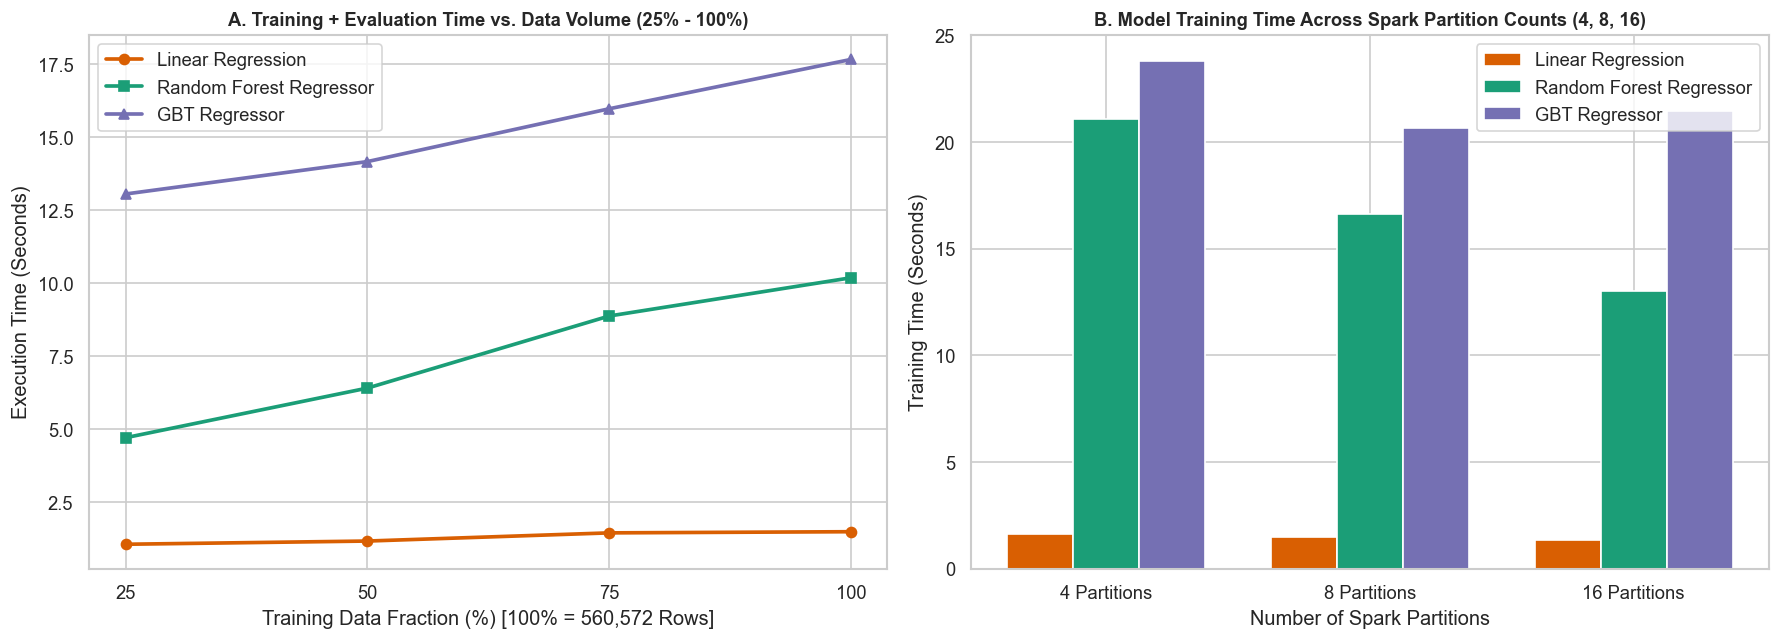

Saved scalability plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\regression_scalability_analysis.png


DataFrame[fips_code: int, Hour: string, year: int, is_onset_hour: double, hours_into_event: double, primary_phenom: string, label_reg: double, tree_features: vector, scaled_features: vector]

In [10]:
# 1. Data-Volume Scalability Experiment (25%, 50%, 75%, 100% of Training Set)
scale_fractions = [0.25, 0.50, 0.75, 1.00]
reg_vol_records = []

for frac in scale_fractions:
    sub_train = train_prep if frac == 1.0 else train_prep.sample(withReplacement=False, fraction=frac, seed=RANDOM_SEED).cache()
    n_rows = sub_train.count()

    t0 = time.time()
    m_lr = LinearRegression(featuresCol="scaled_features", labelCol="label_reg", regParam=best_lr_params["regParam"], elasticNetParam=best_lr_params["elasticNetParam"], maxIter=100).fit(sub_train)
    rmse_lr = eval_rmse.evaluate(m_lr.transform(test_prep))
    t_lr = time.time() - t0

    t0 = time.time()
    m_rf = RandomForestRegressor(featuresCol="tree_features", labelCol="label_reg", numTrees=20, maxDepth=8, subsamplingRate=0.8, featureSubsetStrategy="onethird", seed=RANDOM_SEED).fit(sub_train)
    rmse_rf = eval_rmse.evaluate(m_rf.transform(test_prep))
    t_rf = time.time() - t0

    t0 = time.time()
    m_gbt = GBTRegressor(featuresCol="tree_features", labelCol="label_reg", maxIter=20, maxDepth=5, stepSize=0.1, subsamplingRate=0.8, seed=RANDOM_SEED).fit(sub_train)
    rmse_gbt = eval_rmse.evaluate(m_gbt.transform(test_prep))
    t_gbt = time.time() - t0

    if frac < 1.0:
        sub_train.unpersist()

    reg_vol_records.append({
        "Scale_Pct": int(frac * 100),
        "Train_Rows": n_rows,
        "LR_Time_s": round(t_lr, 2),
        "RF_Time_s": round(t_rf, 2),
        "GBT_Time_s": round(t_gbt, 2),
        "LR_Test_RMSE": round(rmse_lr, 4),
        "RF_Test_RMSE": round(rmse_rf, 4),
        "GBT_Test_RMSE": round(rmse_gbt, 4),
    })

reg_vol_df = pd.DataFrame(reg_vol_records)
print("=== Regression Data-Volume Scalability Benchmark (25% to 100% Training Data) ===")
print(reg_vol_df.to_string(index=False))

# 2. Spark Partition Parallelism Experiment (4, 8, 16 Partitions)
partition_counts = [4, 8, 16]
reg_part_records = []

for n_part in partition_counts:
    part_train = train_prep.repartition(n_part).cache()
    _ = part_train.count()

    t0 = time.time()
    _ = LinearRegression(featuresCol="scaled_features", labelCol="label_reg", regParam=best_lr_params["regParam"], elasticNetParam=best_lr_params["elasticNetParam"], maxIter=100).fit(part_train)
    t_lr = time.time() - t0

    t0 = time.time()
    _ = RandomForestRegressor(featuresCol="tree_features", labelCol="label_reg", numTrees=20, maxDepth=8, subsamplingRate=0.8, featureSubsetStrategy="onethird", seed=RANDOM_SEED).fit(part_train)
    t_rf = time.time() - t0

    t0 = time.time()
    _ = GBTRegressor(featuresCol="tree_features", labelCol="label_reg", maxIter=20, maxDepth=5, stepSize=0.1, subsamplingRate=0.8, seed=RANDOM_SEED).fit(part_train)
    t_gbt = time.time() - t0

    part_train.unpersist()
    reg_part_records.append({
        "Spark_Partitions": n_part,
        "LR_Time_s": round(t_lr, 2),
        "RF_Time_s": round(t_rf, 2),
        "GBT_Time_s": round(t_gbt, 2),
    })

reg_part_df = pd.DataFrame(reg_part_records)
print("\n=== Regression Spark Partition Parallelism Benchmark (4, 8, 16 Partitions) ===")
print(reg_part_df.to_string(index=False))

reg_vol_df.to_csv(OUTPUT_DIR / "regression_scalability_volume.csv", index=False)
reg_part_df.to_csv(OUTPUT_DIR / "regression_scalability_partitions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(reg_vol_df["Scale_Pct"], reg_vol_df["LR_Time_s"], "o-", lw=2.2, color="#d95f02", label="Linear Regression")
axes[0].plot(reg_vol_df["Scale_Pct"], reg_vol_df["RF_Time_s"], "s-", lw=2.2, color="#1b9e77", label="Random Forest Regressor")
axes[0].plot(reg_vol_df["Scale_Pct"], reg_vol_df["GBT_Time_s"], "^-", lw=2.2, color="#7570b3", label="GBT Regressor")
axes[0].set_title("A. Training + Evaluation Time vs. Data Volume (25% - 100%)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Training Data Fraction (%) [100% = 560,572 Rows]")
axes[0].set_ylabel("Execution Time (Seconds)")
axes[0].set_xticks([25, 50, 75, 100])
axes[0].legend()

x_pos = np.arange(len(reg_part_df["Spark_Partitions"]))
width = 0.25
axes[1].bar(x_pos - width, reg_part_df["LR_Time_s"], width=width, color="#d95f02", label="Linear Regression")
axes[1].bar(x_pos, reg_part_df["RF_Time_s"], width=width, color="#1b9e77", label="Random Forest Regressor")
axes[1].bar(x_pos + width, reg_part_df["GBT_Time_s"], width=width, color="#7570b3", label="GBT Regressor")
axes[1].set_title("B. Model Training Time Across Spark Partition Counts (4, 8, 16)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Number of Spark Partitions")
axes[1].set_ylabel("Training Time (Seconds)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f"{p} Partitions" for p in reg_part_df["Spark_Partitions"]])
axes[1].legend()

plt.tight_layout()
scale_fig_path = OUTPUT_DIR / "regression_scalability_analysis.png"
plt.savefig(scale_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved scalability plot to: {scale_fig_path}")

lr_test_preds.unpersist()
rf_test_preds.unpersist()
gbt_test_preds.unpersist()
train_prep.unpersist()
val_prep.unpersist()
test_prep.unpersist()

## 13. Limitations and Conclusion

### 13.1 Limitations
1. **Weather-Alert Conditioning:** `Eagle_I_US_2024_with_VTEC_Updated.csv` only includes hours where an outage overlapped with an active NWS weather warning (`Matched_Count >= 1`). The models therefore apply to weather-related outages rather than clear-sky equipment faults.
2. **Completeness Filtering:** Training and evaluating on the `100% Complete` telemetry tier avoids missing-data bias, but utilities with frequent telemetry dropouts during severe storms are less represented.
3. **1-Hour Forecast Horizon:** All three models use the preceding hour's outage level ($t-1$) for 1-hour-ahead prediction. Multi-hour-ahead forecasting without intermediate telemetry updates would have higher error.

### 13.2 Conclusion
All three PySpark regression models generalized well to the held-out **2022-2023 test set** ($135,945$ county-hours):
- **Gradient-Boosted Tree Regressor (`GBTRegressor`)** achieved the best overall test performance (**MAE = `0.2947`**, **RMSE = `0.5324`**, **$R^2 = 0.9332$**), followed by **Random Forest Regressor** (**MAE = `0.3176`**, **RMSE = `0.5474`**, **$R^2 = 0.9293$**) and **Linear Regression** (**MAE = `0.3212`**, **RMSE = `0.5575`**, **$R^2 = 0.9267$**).
- Tree ensemble models provide the largest accuracy gain during the early hours of an outage ($1 \le h \le 3$), where non-linear interactions between initial outage shock, recent momentum, and county baseline matter most, while Linear Regression offers the fastest execution speed in distributed Spark benchmarks.